### Setups and Load data

In [1]:
from pathlib import Path
import numpy as np
import pandas
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
import os
from matplotlib.patches import Patch

os.makedirs("../figures/point_cloud", exist_ok=True)

LABELS = [9, 10, 11]

DIST_CROSS_DORN = r"../../Experiments/dorn_warm/dorn_warm_Dist_Cross"
DIST_CROSS_PERSONAI = r"../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey" 
DIST_DORN = r"../../Experiments/dorn_warm/dorn_warm_Cross"
DIST_PERSONAI = r"../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey"
AGREE_PERSONAI = r"../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness"
AGREE_DORN = r"../../Experiments/dorn_cold/dorn_cold_agreeableness"
SWLS_PERSONAI = r"../../Experiments/PersonAI_cold/PersonAI_cold_swls_score"
SWLS_DORN = r"../../Experiments/dorn_cold/dorn_cold_swls"

### helper functions

In [2]:
def load_all_preds(exp, patterns):
    dfs = []
    for it in Path(exp).iterdir():
        if not it.is_dir():
            print(f"Skipping {it}: no matching file")
            continue
        f = next((p for pat in patterns for p in sorted(it.glob(pat))), None)
        if f is None:
            continue
        df = pd.read_csv(f)
        df.columns = df.columns.str.strip().str.replace("\ufeff", "")
        dfs.append(df[["user", "true", "pred"]])
    return pd.concat(dfs, ignore_index=True) if dfs else None


def per_user_f1_micro(df):
    return df.groupby("user").apply(
        lambda g: f1_score(g["true"].astype(int), g["pred"].astype(int), average="micro")
    ).astype(float)


def pct_change_vs_general(general_f1, cohort_f1):
    common = general_f1.index.intersection(cohort_f1.index)

    base = general_f1.loc[common].to_numpy(dtype=float)
    coh  = cohort_f1.loc[common].to_numpy(dtype=float)
    delta = 100.0 * (coh - base) / base
    return common.to_numpy(), delta


def plot_paper_style(delta_by_label, title, out_file, out_dir="../figures/point_cloud"):
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    labels = list(delta_by_label.keys())
    data = [np.asarray(delta_by_label[k], float) for k in labels]

    pd.DataFrame({
        label: pd.Series(vals)
        for label, vals in zip(labels, data)
    }).describe().to_csv(
        out_dir / Path(out_file).with_suffix(".csv").name
    )

    box_colors = {
        "DORN:Dist-Cross":               "#6B2737",
        "DORN:Cross":               "#6B2737",
        "DORN:SWLS":              "#6B2737",
        "DORN:Agreeableness":     "#6B2737",
        "PersonAI:Dist-Cross":           "#6B2737",
        "PersonAI:Cross":           "#6B2737",
        "PersonAI:SWLS":          "#6B2737",
        "PersonAI:Agreeableness": "#6B2737",
    }

    fig, ax = plt.subplots(figsize=(12, 4))

    bp = ax.boxplot(
        data,
        vert=False,
        labels=labels,
        showfliers=False,
        patch_artist=True,
        widths=0.55,
        medianprops=dict(color="black", linewidth=1.5)
    )

    for patch, label in zip(bp["boxes"], labels):
        patch.set_facecolor(box_colors.get(label, "#999999"))
        patch.set_alpha(0.5)

    rng = np.random.default_rng(42)
    for i, vals in enumerate(data, start=1):
        y = i + rng.uniform(-0.18, 0.18, size=len(vals))
        ax.scatter(
            vals,
            y,
            s=22,
            alpha=0.85,
            color="#333333"
        )

    ax.set_xlabel("Average percentage [%] change in F1-micro")
    ax.set_ylabel("Dataset")
    #ax.set_title(title)
    ax.grid(False)
    plt.grid(False)


    fig.tight_layout()
    fig.savefig(out_dir / out_file, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### calculate delta

In [3]:
#Cross-Dist
#PersonAI
df_gen_p = load_all_preds(DIST_CROSS_PERSONAI, ["*baseline_predictions.csv"])
df_coh_p = load_all_preds(DIST_CROSS_PERSONAI, ["*cluster_predictions.csv"])

gen_f1_p = per_user_f1_micro(df_gen_p)
coh_f1_p = per_user_f1_micro(df_coh_p)
users_p, delta_p = pct_change_vs_general(gen_f1_p, coh_f1_p)

#DORN
df_gen_d = load_all_preds(DIST_CROSS_DORN, ["*baseline_predictions.csv"])
df_coh_d = load_all_preds(DIST_CROSS_DORN, ["*cluster_predictions.csv"])

gen_f1_d = per_user_f1_micro(df_gen_d)
coh_f1_d = per_user_f1_micro(df_coh_d)
users_d, delta_d = pct_change_vs_general(gen_f1_d, coh_f1_d)

print("DORN:")
print(" Baseline min:", gen_f1_d.min())
print(" Baseline max:", gen_f1_d.max())
print(" Baseline mean:", gen_f1_d.mean())
print(" Cohort min:", coh_f1_d.min())
print(" Cohort max:", coh_f1_d.max())
print(" Cohort mean:", coh_f1_d.mean())

print("PersonAI:")
print(" Baseline min:", gen_f1_p.min())
print(" Baseline max:", gen_f1_p.max())
print(" Baseline mean:", gen_f1_p.mean())
print(" Cohort min:", coh_f1_p.min())
print(" Cohort max:", coh_f1_p.max())
print(" Cohort mean:", coh_f1_p.mean())

Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter56_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter42_dict_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter22_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter34_dict_test_acc_performance_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter23_cluster_metrics.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/iter32_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey/it

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(


Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter9_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter1_0.5-0.pdf: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter7_dict_test_label_performance.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter18_dict_baseline_pcm_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter14_dict_test_acc_performance_f1_micro.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter13_dict_test_acc_performance_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter12_cluster_metrics.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Dist_Cross/iter13_df_cross_model_

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(


In [4]:
#Dist
#PersonAI
df_dist_gen_p = load_all_preds(DIST_PERSONAI, ["*baseline_predictions.csv"])
df_dist_coh_p = load_all_preds(DIST_PERSONAI, ["*cluster_predictions.csv"])

gen_dist_f1_p = per_user_f1_micro(df_dist_gen_p)
coh_dist_f1_p = per_user_f1_micro(df_dist_coh_p)
users_dist_p, delta_dist_p = pct_change_vs_general(gen_dist_f1_p, coh_dist_f1_p)

#DORN
df_dist_gen_d = load_all_preds(DIST_DORN, ["*baseline_predictions.csv"])
df_dist_coh_d = load_all_preds(DIST_DORN, ["*cluster_predictions.csv"])

gen_dist_f1_d = per_user_f1_micro(df_dist_gen_d)
coh_dist_f1_d = per_user_f1_micro(df_dist_coh_d)
users_dist_d, delta_dist_d = pct_change_vs_general(gen_dist_f1_d, coh_dist_f1_d)

print("DORN Dist:")
print(" Baseline min:", gen_dist_f1_d.min())
print(" Baseline max:", gen_dist_f1_d.max())
print(" Baseline mean:", gen_dist_f1_d.mean())
print(" Cohort min:", coh_dist_f1_d.min())
print(" Cohort max:", coh_dist_f1_d.max())
print(" Cohort mean:", coh_dist_f1_d.mean())

print("PersonAI Dist:")
print(" Baseline min:", gen_dist_f1_p.min())
print(" Baseline max:", gen_dist_f1_p.max())
print(" Baseline mean:", gen_dist_f1_p.mean())
print(" Cohort min:", coh_dist_f1_p.min())
print(" Cohort max:", coh_dist_f1_p.max())
print(" Cohort mean:", coh_dist_f1_p.mean())

Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter56_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter42_dict_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter22_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter34_dict_test_acc_performance_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter23_cluster_metrics.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter32_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_warm/PersonAI_warm_Dist_survey/iter9_dict_baseline_pcm_acc_rdf_f1_micro.pickle: n

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping 

Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter9_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter7_dict_test_label_performance.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter18_dict_baseline_pcm_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter14_dict_test_acc_performance_f1_micro.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter13_dict_test_acc_performance_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter7_0-0.pdf: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter12_cluster_metrics.pickle: no matching file
Skipping ../../Experiments/dorn_warm/dorn_warm_Cross/iter13_df_cross_model_performance_rdf.pickle: no matching file
Skippi

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(


In [5]:
#agreeableness
#PersonAI
df_agree_gen_p = load_all_preds(AGREE_PERSONAI, ["*baseline_predictions.csv"])
df_agree_coh_p = load_all_preds(AGREE_PERSONAI, ["*cluster_predictions.csv"])

gen_agree_f1_p = per_user_f1_micro(df_agree_gen_p)
coh_agree_f1_p = per_user_f1_micro(df_agree_coh_p)
users_agree_p, delta_agree_p = pct_change_vs_general(gen_agree_f1_p, coh_agree_f1_p)

#DORN
df_agree_gen_d = load_all_preds(AGREE_DORN, ["*baseline_predictions.csv"])
df_agree_coh_d = load_all_preds(AGREE_DORN, ["*cluster_predictions.csv"])

gen_agree_f1_d = per_user_f1_micro(df_agree_gen_d)
coh_agree_f1_d = per_user_f1_micro(df_agree_coh_d)
users_agree_d, delta_agree_d = pct_change_vs_general(gen_agree_f1_d, coh_agree_f1_d)

print("DORN Agreeableness:")
print(" Baseline min:", gen_agree_f1_d.min())
print(" Baseline max:", gen_agree_f1_d.max())
print(" Baseline mean:", gen_agree_f1_d.mean())
print(" Cohort min:", coh_agree_f1_d.min())
print(" Cohort max:", coh_agree_f1_d.max())
print(" Cohort mean:", coh_agree_f1_d.mean())

print("PersonAI Agreeableness:")
print(" Baseline min:", gen_agree_f1_p.min())
print(" Baseline max:", gen_agree_f1_p.max())
print(" Baseline mean:", gen_agree_f1_p.mean())
print(" Cohort min:", coh_agree_f1_p.min())
print(" Cohort max:", coh_agree_f1_p.max())
print(" Cohort mean:", coh_agree_f1_p.mean())

Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter56_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter36_dict_test_acc_questions_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter22_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter32_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter9_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s_agreeableness/iter22_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_bfi2s

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping 

In [6]:
#SWLS
#PersonAI
df_swls_gen_p = load_all_preds(SWLS_PERSONAI, ["*baseline_predictions.csv"])
df_swls_coh_p = load_all_preds(SWLS_PERSONAI, ["*cluster_predictions.csv"])

gen_swls_f1_p = per_user_f1_micro(df_swls_gen_p)
coh_swls_f1_p = per_user_f1_micro(df_swls_coh_p)
users_swls_p, delta_swls_p = pct_change_vs_general(gen_swls_f1_p, coh_swls_f1_p)

#DORN
df_swls_gen_d = load_all_preds(SWLS_DORN, ["*baseline_predictions.csv"])
df_swls_coh_d = load_all_preds(SWLS_DORN, ["*cluster_predictions.csv"])

gen_swls_f1_d = per_user_f1_micro(df_swls_gen_d)
coh_swls_f1_d = per_user_f1_micro(df_swls_coh_d)
users_swls_d, delta_swls_d = pct_change_vs_general(gen_swls_f1_d, coh_swls_f1_d)

print("DORN SWLS:")
print(" Baseline min:", gen_swls_f1_d.min())
print(" Baseline max:", gen_swls_f1_d.max())
print(" Baseline mean:", gen_swls_f1_d.mean())
print(" Cohort min:", coh_swls_f1_d.min())
print(" Cohort max:", coh_swls_f1_d.max())
print(" Cohort mean:", coh_swls_f1_d.mean())


print("PersonAI SWLS:")
print(" Baseline min:", gen_swls_f1_p.min())
print(" Baseline max:", gen_swls_f1_p.max())
print(" Baseline mean:", gen_swls_f1_p.mean())
print(" Cohort min:", coh_swls_f1_p.min())
print(" Cohort max:", coh_swls_f1_p.max())
print(" Cohort mean:", coh_swls_f1_p.mean())

Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter56_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter36_dict_test_acc_questions_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter22_dict_baseline_acc_rdf_cohen_kappa.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter8_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter32_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter9_dict_baseline_pcm_acc_rdf_f1_micro.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter22_test_users.pickle: no matching file
Skipping ../../Experiments/PersonAI_cold/PersonAI_cold_swls_score/iter55_dict_cluster_qns.pickle: no matching file
Skipping

/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("user").apply(
/tmp/ipykernel_49271/602547722.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping 

### plots

In [7]:
# pd.Series(delta_dist_d).describe()
# delta_dist_d

/tmp/ipykernel_49271/602547722.py:58: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


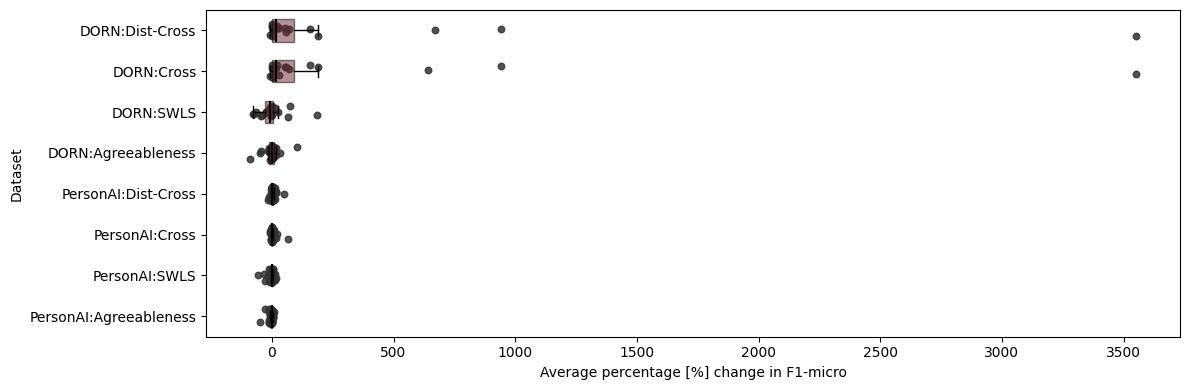

PersonAI improved: 0.4722222222222222
DORN improved: 0.8


In [7]:
plot_paper_style(
    {  "PersonAI:Agreeableness": delta_agree_p,"PersonAI:SWLS": delta_swls_p, "PersonAI:Cross": delta_dist_p, "PersonAI:Dist-Cross": delta_p,"DORN:Agreeableness": delta_agree_d,"DORN:SWLS": delta_swls_d,"DORN:Cross": delta_dist_d, "DORN:Dist-Cross": delta_d},
    title="Participant-specific vs General-purpose (F1-micro % change)",
    out_file="point_clouds_personai_dorn.pdf"
)

print("PersonAI improved:", (delta_p > 0).mean())
print("DORN improved:", (delta_d > 0).mean())

In [8]:
common_d = gen_f1_d.index.intersection(coh_f1_d.index)
base_d = gen_f1_d.loc[common_d].to_numpy(float)
coh_d  = coh_f1_d.loc[common_d].to_numpy(float)
delta_d = 100*(coh_d-base_d)/base_d

common_p = gen_f1_p.index.intersection(coh_f1_p.index)
base_p = gen_f1_p.loc[common_p].to_numpy(float)
coh_p  = coh_f1_p.loc[common_p].to_numpy(float)
delta_p = 100*(coh_p-base_p)/base_p

mask_d = delta_d > 90
mask_p = delta_p > 90

for u, b, c, d in zip(common_d[mask_d], base_d[mask_d], coh_d[mask_d], delta_d[mask_d]):
    print("User:", u)
    print("baseline f1:", b)
    print("cohort f1:", c)
    print("delta %:", d, '\n')

for u, b, c, d in zip(common_p[mask_p], base_p[mask_p], coh_p[mask_p], delta_p[mask_p]):
    print("User:", u)
    print("baseline f1:", b)
    print("cohort f1:", c)
    print("delta %:", d, '\n')




User: dorn10
baseline f1: 0.025974025974025976
cohort f1: 0.948051948051948
delta %: 3550.0 

User: dorn14
baseline f1: 0.0735930735930736
cohort f1: 0.7662337662337663
delta %: 941.1764705882354 

User: dorn16
baseline f1: 0.12121212121212122
cohort f1: 0.935064935064935
delta %: 671.4285714285714 

User: dorn2
baseline f1: 0.17316017316017315
cohort f1: 0.4458874458874459
delta %: 157.5 

User: dorn4
baseline f1: 0.16017316017316016
cohort f1: 0.46320346320346323
delta %: 189.18918918918922 



/tmp/ipykernel_49271/602547722.py:58: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


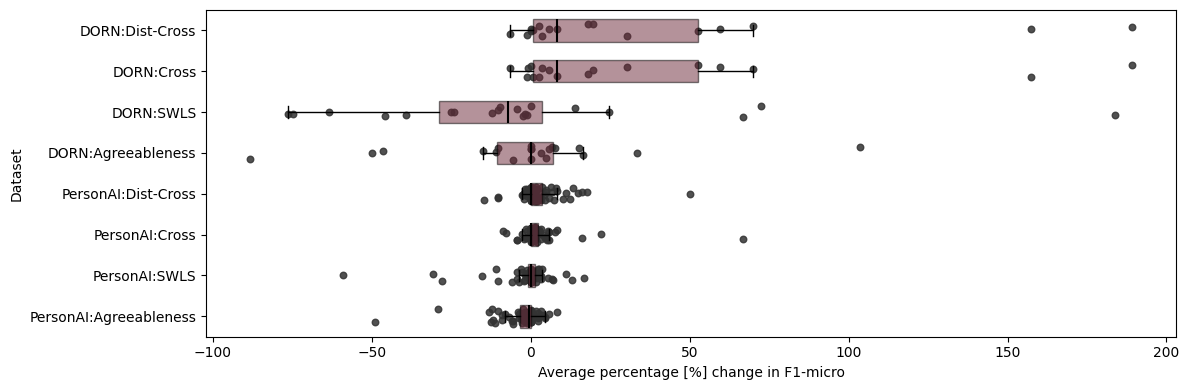

PersonAI improved: 0.4722222222222222
DORN improved: 0.8


In [9]:
delta_d_limited = delta_d[delta_d < 200]
delta_dist_d_limited = delta_dist_d[delta_dist_d < 200]
plot_paper_style(
    {  "PersonAI:Agreeableness": delta_agree_p,"PersonAI:SWLS": delta_swls_p, "PersonAI:Cross": delta_dist_p, "PersonAI:Dist-Cross": delta_p,"DORN:Agreeableness": delta_agree_d,"DORN:SWLS": delta_swls_d,"DORN:Cross": delta_dist_d_limited, "DORN:Dist-Cross": delta_d_limited},
    title="Participant-specific vs General-purpose (F1-micro % change) limited to gaps under 200%",
    out_file="point_clouds_personai_dorn_limited200.pdf"
)

print("PersonAI improved:", (delta_p > 0).mean())
print("DORN improved:", (delta_d > 0).mean())